## STEP 1: DATA COLLECTION

### Dataset Title
Life Expectancy Dataset

### Application Area
Global health and development analysis

### Why this dataset was chosen
This dataset is suitable for multivariate analysis because it contains many numerical variables related to health, economics, and demographics across countries and years. It is large enough for exploratory analysis, dimensionality reduction, clustering, discriminant analysis, machine learning, and dashboard development.

### Unit of Observation
Each row represents a country in a given year.

### Target Variable
Life expectancy

### Main Features
Adult Mortality, infant deaths, Alcohol, percentage expenditure, Hepatitis B, Measles, BMI, under-five deaths, Polio, Total expenditure, Diphtheria, HIV/AIDS, GDP, Population, thinness, Income composition of resources, Schooling.

In [12]:
# Step 1: Import needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
 

In [13]:

file_path = r"C:\Users\Admin\Documents\le\Life-expectancy-dashboard-\data\raw\Life Expectancy Data.csv"

print(os.path.exists(file_path))   # should return True

df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()
df.head()

True


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


 ###  **STEP 2: EXPLORATORY DATA ANALYSIS (EDA)**

In [14]:

# 1. Dataset Shape
print(" Dataset Shape (Rows, Columns):")
print(df.shape)



 Dataset Shape (Rows, Columns):
(2938, 22)


In [15]:
# 2. Column Names
print("\n Columns in Dataset:")
print(df.columns.tolist())




 Columns in Dataset:
['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


In [16]:
# 3. Data Types & Info
print("\n Dataset Information:")
df.info()




 Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 1

**Summary Statistics**

In [17]:

# 4. Summary Statistics
print("\n Summary Statistics:")
print(df.describe())



 Summary Statistics:
              Year  Life expectancy  Adult Mortality  infant deaths  \
count  2938.000000      2928.000000      2928.000000    2938.000000   
mean   2007.518720        69.224932       164.796448      30.303948   
std       4.613841         9.523867       124.292079     117.926501   
min    2000.000000        36.300000         1.000000       0.000000   
25%    2004.000000        63.100000        74.000000       0.000000   
50%    2008.000000        72.100000       144.000000       3.000000   
75%    2012.000000        75.700000       228.000000      22.000000   
max    2015.000000        89.000000       723.000000    1800.000000   

           Alcohol  percentage expenditure  Hepatitis B        Measles  \
count  2744.000000             2938.000000  2385.000000    2938.000000   
mean      4.602861              738.251295    80.940461    2419.592240   
std       4.052413             1987.914858    25.070016   11467.272489   
min       0.010000                0.000000

**Missing Values**

In [18]:
# 5. Missing Values
print("\n Missing Values in Each Column:")
missing_values = df.isnull().sum()
display(missing_values)




 Missing Values in Each Column:


Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
BMI                                 34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness  1-19 years                34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64

#### **Handling Missing Values**

In [19]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage = missing_percentage.sort_values(ascending=False)
print(missing_percentage)

Population                         22.191967
Hepatitis B                        18.822328
GDP                                15.248468
Total expenditure                   7.692308
Alcohol                             6.603131
Income composition of resources     5.684139
Schooling                           5.547992
thinness 5-9 years                  1.157250
thinness  1-19 years                1.157250
BMI                                 1.157250
Polio                               0.646698
Diphtheria                          0.646698
Life expectancy                     0.340368
Adult Mortality                     0.340368
HIV/AIDS                            0.000000
Country                             0.000000
Year                                0.000000
Measles                             0.000000
percentage expenditure              0.000000
infant deaths                       0.000000
Status                              0.000000
under-five deaths                   0.000000
dtype: flo

We don't drop columns because:
Missing < 30%
Important variables (GDP, Population)
Instead we fill with mean

**Fiiling with Mean**

In [20]:
# Select numeric columns only
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Fill missing values with mean
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())
print(df.isna().sum())

Country                            0
Year                               0
Status                             0
Life expectancy                    0
Adult Mortality                    0
infant deaths                      0
Alcohol                            0
percentage expenditure             0
Hepatitis B                        0
Measles                            0
BMI                                0
under-five deaths                  0
Polio                              0
Total expenditure                  0
Diphtheria                         0
HIV/AIDS                           0
GDP                                0
Population                         0
thinness  1-19 years               0
thinness 5-9 years                 0
Income composition of resources    0
Schooling                          0
dtype: int64


In [21]:

# 6. Check Duplicate Rows
print("\n Duplicate Rows:")
print(df.duplicated().sum())


 Duplicate Rows:
0


### **country data load**

In [26]:
coords = pd.read_csv(r"C:\Users\Admin\Documents\le\Life-expectancy-dashboard-\data\raw\countries.csv")
coords = coords[['name','latitude','longitude']]
coords.columns = ['Country','Latitude','Longitude']
coords.head()

,Country,Latitude,Longitude
0,Afghanistan,33.000000,65.0
1,Aland Islands,60.116667,19.9
2,Albania,41.000000,20.0
3,Algeria,28.000000,3.0
4,American Samoa,-14.333333,-170.0


### **Merging Datas**

In [27]:


df = pd.merge(df, coords, on='Country', how='left')
df.head()


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Latitude_x,Longitude_x,Latitude_y,Longitude_y
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,584.259210,33736494.0,17.2,17.3,0.479,10.1,33.0,65.0,33.0,65.0
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,612.696514,327582.0,17.5,17.5,0.476,10.0,33.0,65.0,33.0,65.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,631.744976,31731688.0,17.7,17.7,0.470,9.9,33.0,65.0,33.0,65.0
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,669.959000,3696958.0,17.9,18.0,0.463,9.8,33.0,65.0,33.0,65.0
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,63.537231,2978599.0,18.2,18.2,0.454,9.5,33.0,65.0,33.0,65.0


In [30]:
df.to_csv(r"C:\Users\Admin\Documents\le\Life-expectancy-dashboard-\data\processed\cleaned_data.csv", index=False)

## **EDA**

##### **Distrubtion Plots**

**Histogram**

Generating Histograms and Box Plots for Numerical Columns...


c:\Users\Admin\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Admin\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Admin\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Admin\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

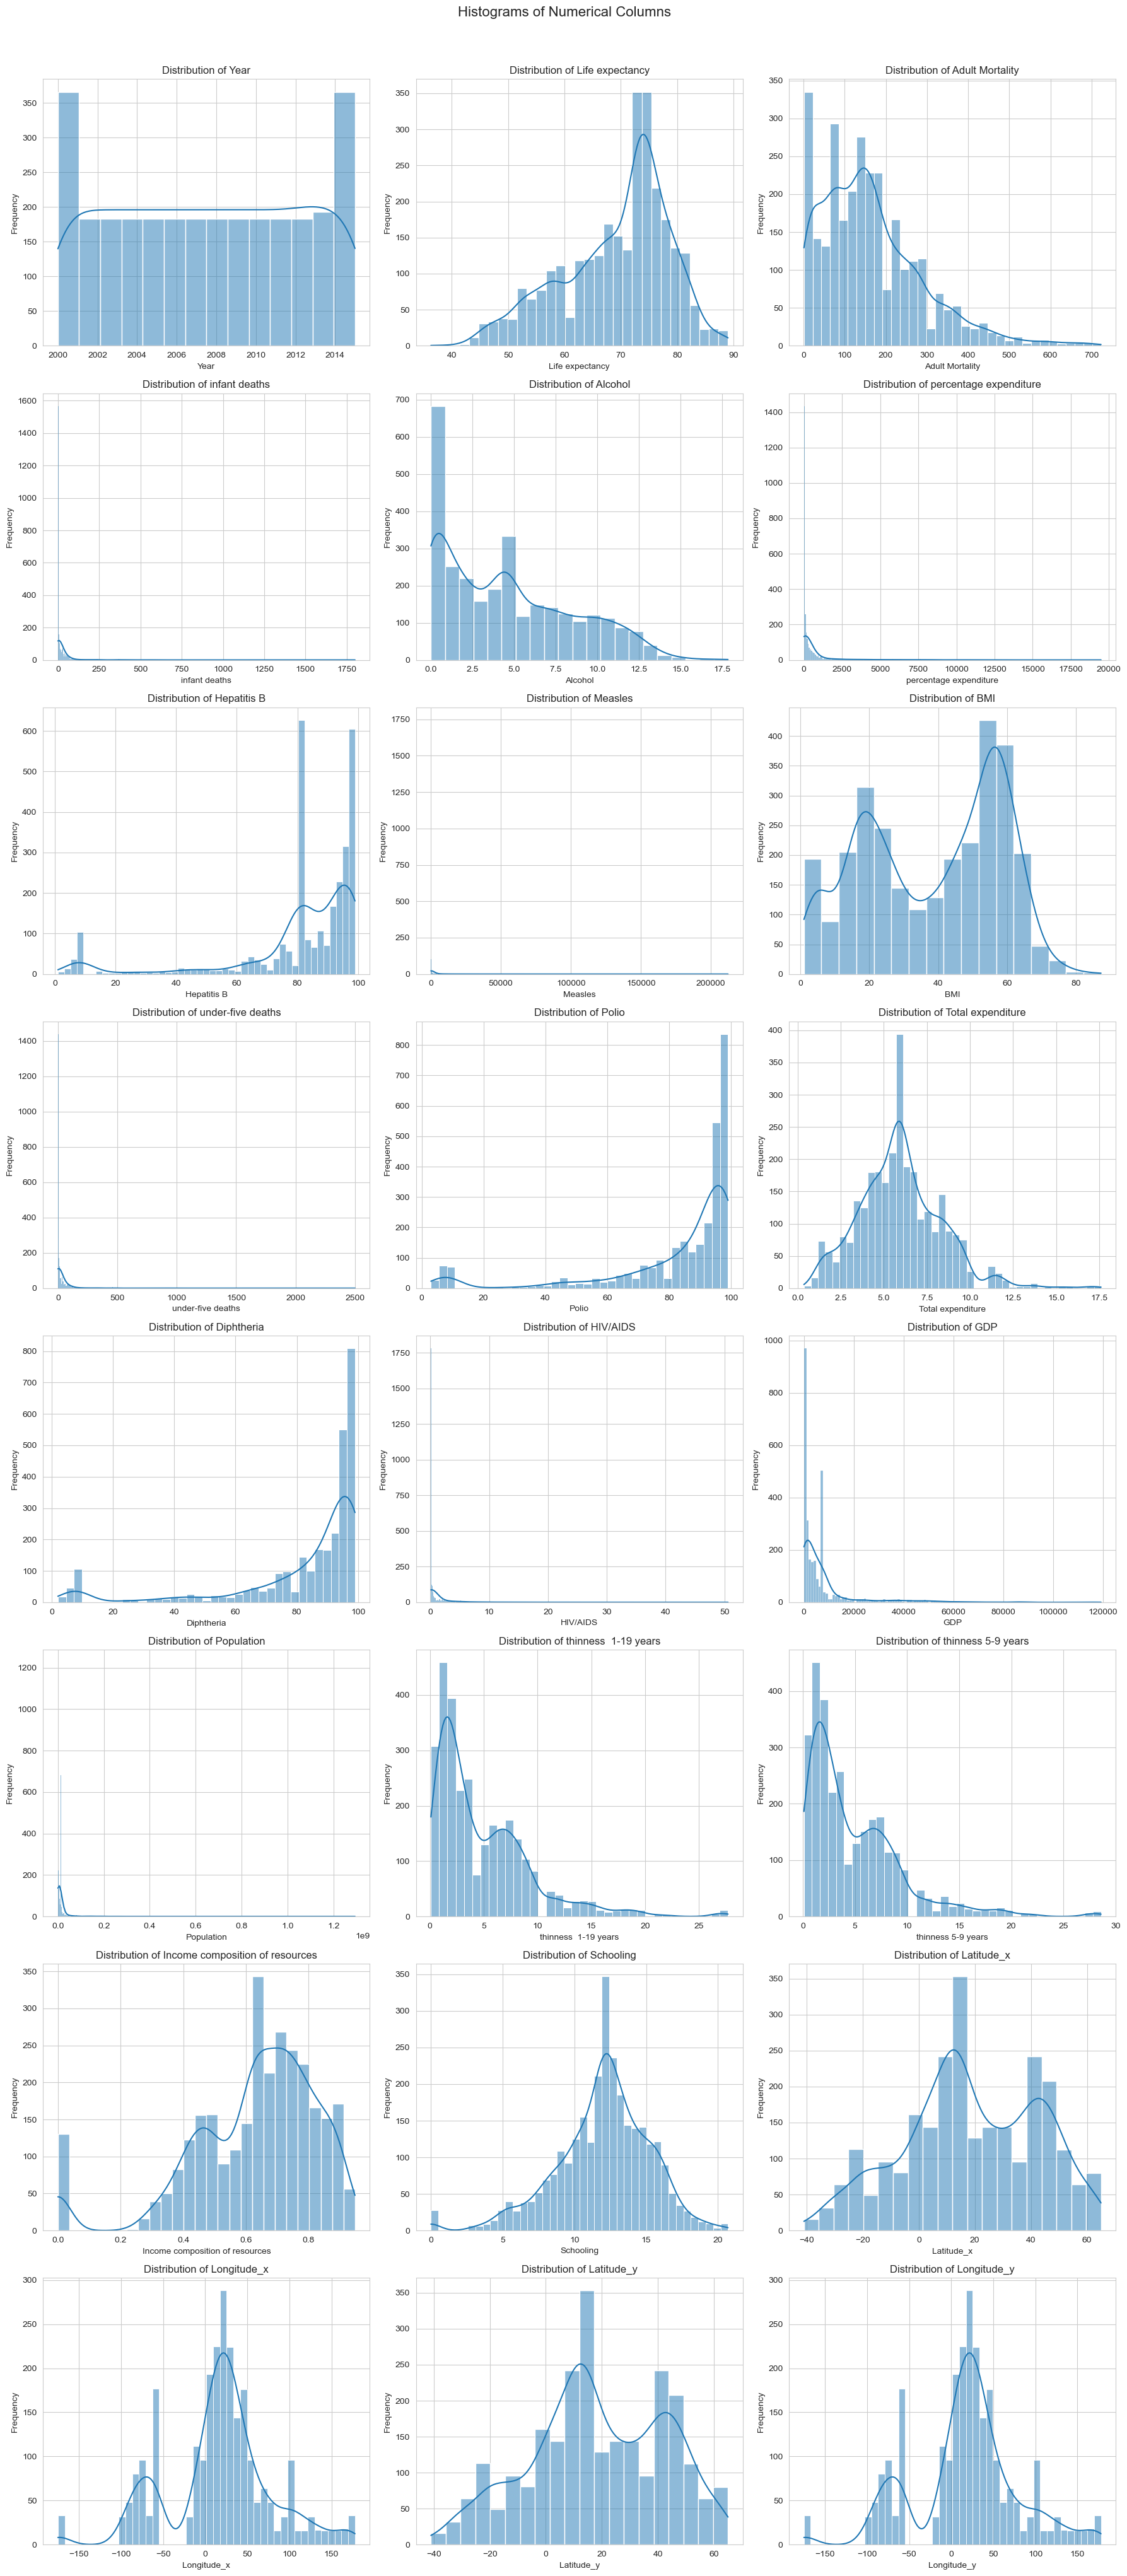

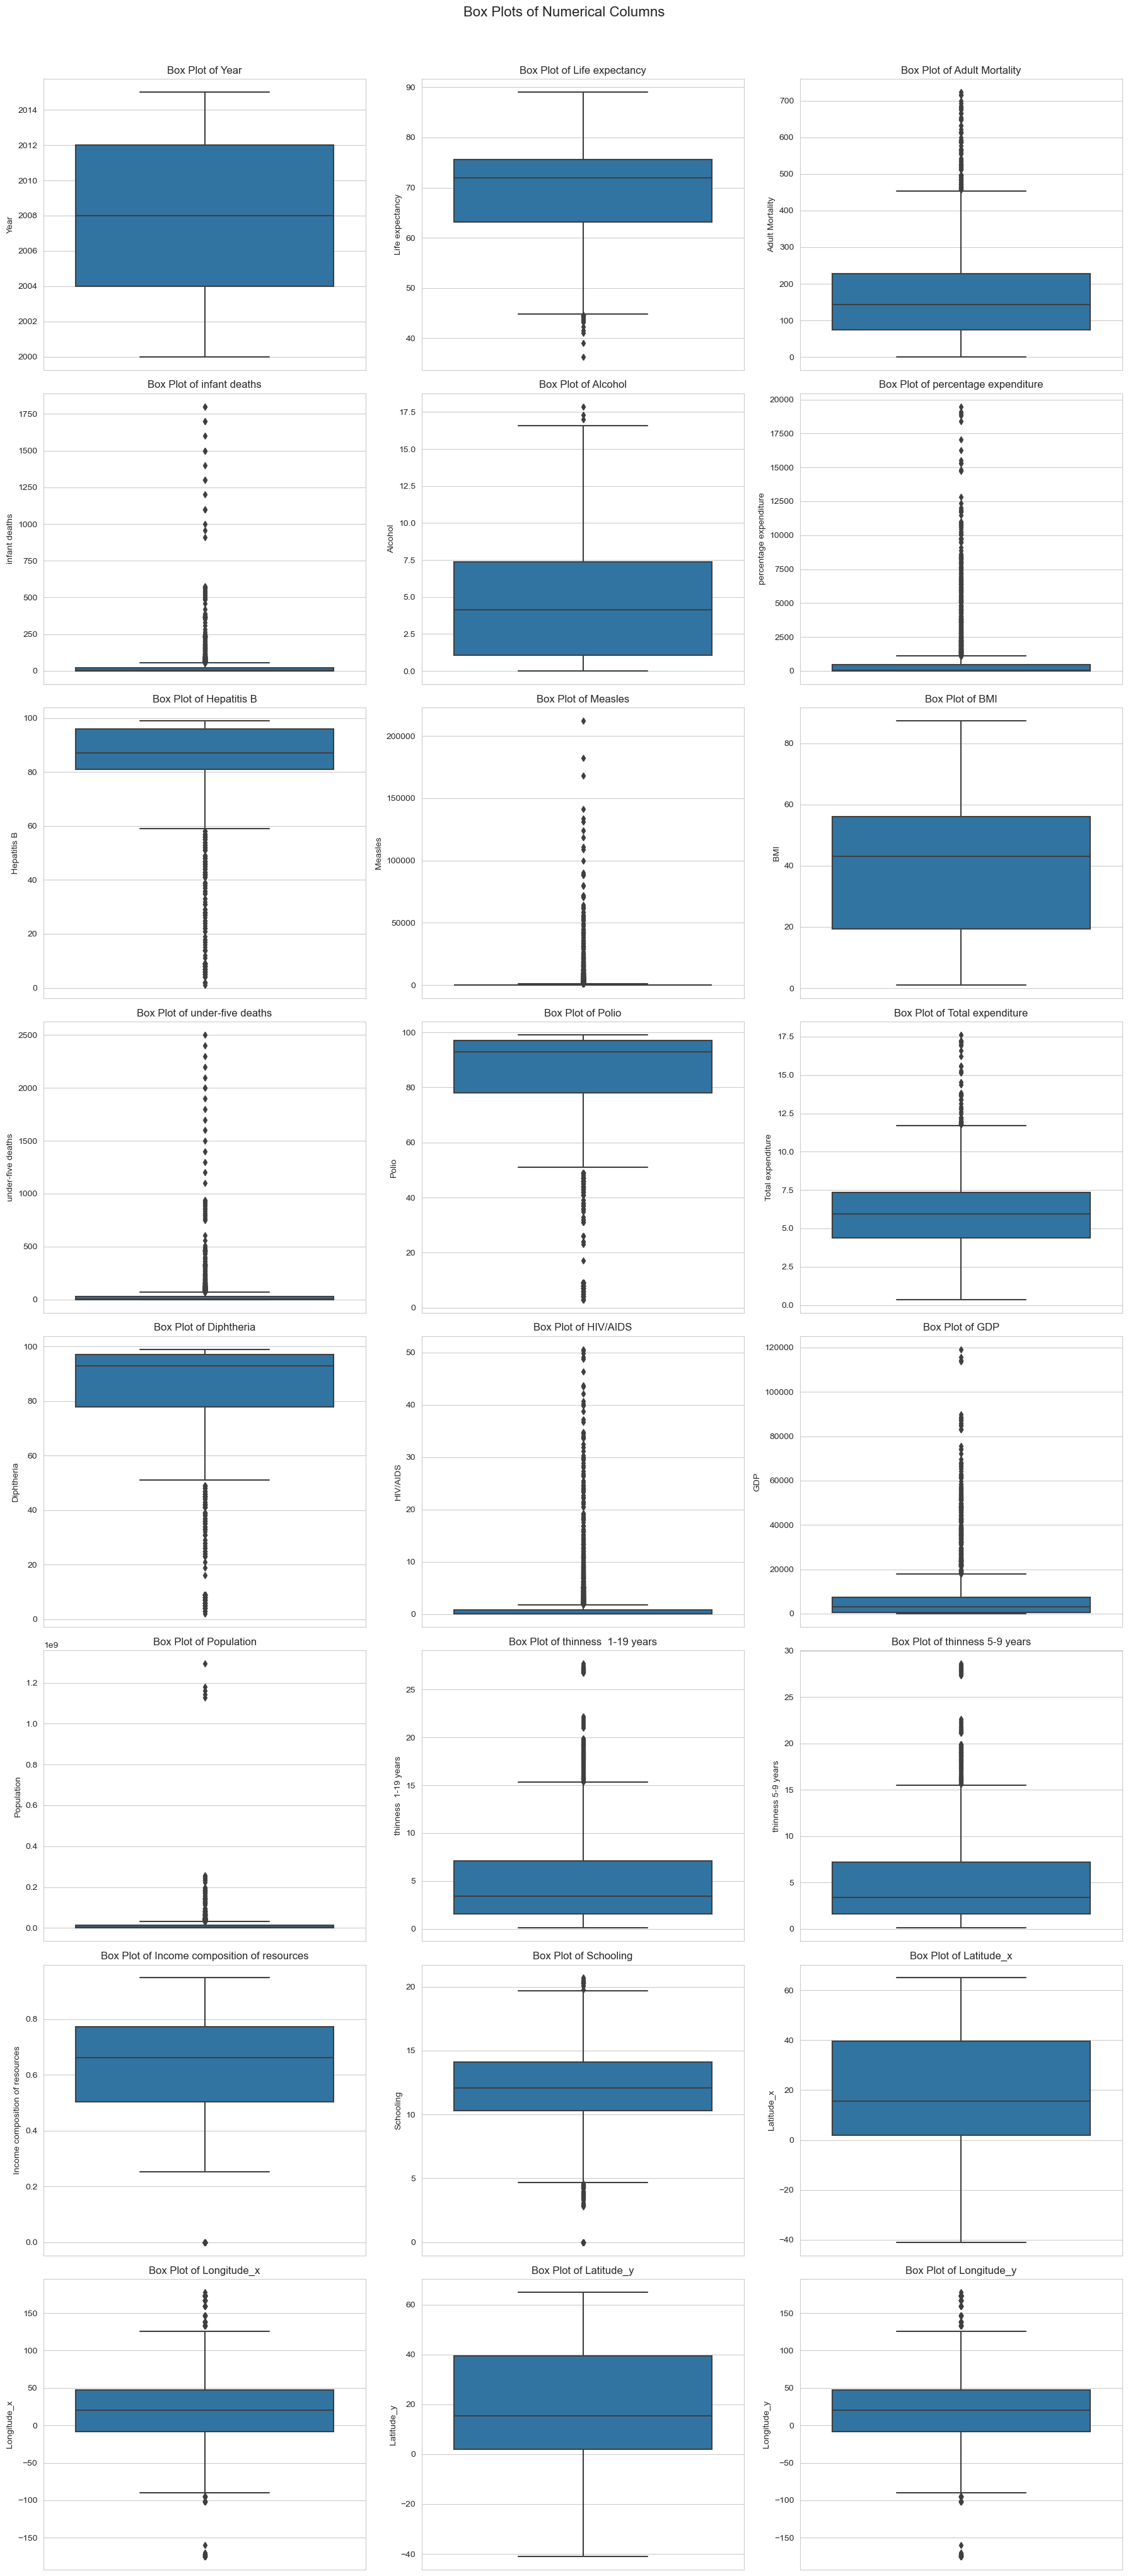

In [29]:
numerical_cols = df.select_dtypes(include=['number']).columns

print("Generating Histograms and Box Plots for Numerical Columns...")

# Set a style for the plots
sns.set_style("whitegrid")

# Create histograms for numerical columns
num_numerical_cols = len(numerical_cols)
fig_hist, axes_hist = plt.subplots(nrows=(num_numerical_cols + 2) // 3, ncols=3, figsize=(18, 5 * ((num_numerical_cols + 2) // 3)))
axes_hist = axes_hist.flatten() # Flatten the 2D array of axes for easy iteration

for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], kde=True, ax=axes_hist[i])
    axes_hist[i].set_title(f'Distribution of {col}', fontsize=12)
    axes_hist[i].set_xlabel(col, fontsize=10)
    axes_hist[i].set_ylabel('Frequency', fontsize=10)

# Hide any unused subplots
for j in range(i + 1, len(axes_hist)):
    fig_hist.delaxes(axes_hist[j])

plt.tight_layout()
plt.suptitle('Histograms of Numerical Columns', y=1.02, fontsize=16)
plt.show()

# Create box plots for numerical columns
fig_box, axes_box = plt.subplots(nrows=(num_numerical_cols + 2) // 3, ncols=3, figsize=(18, 5 * ((num_numerical_cols + 2) // 3)))
axes_box = axes_box.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes_box[i])
    axes_box[i].set_title(f'Box Plot of {col}', fontsize=12)
    axes_box[i].set_ylabel(col, fontsize=10)

# Hide any unused subplots
for j in range(i + 1, len(axes_box)):
    fig_box.delaxes(axes_box[j])

plt.tight_layout()
plt.suptitle('Box Plots of Numerical Columns', y=1.02, fontsize=16)
plt.show();

**Boxplot**

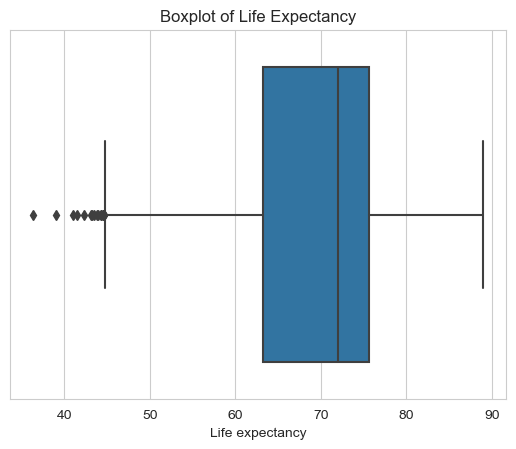

In [ ]:

# 8. Boxplot (Outliers Detection)

plt.figure()
sns.boxplot(x=df["Life expectancy"])
plt.title("Boxplot of Life Expectancy")
plt.show()



#### **Treatment of Outliers**

Outliers were identified in several variables, including infant deaths, measles cases, and economic indicators. These extreme values were not removed, as they represent real-world differences between countries rather than data errors.

Retaining these outliers is important for capturing global inequalities in health and economic conditions. Additionally, multivariate techniques such as PCA and clustering benefit from the presence of such variation, as they help reveal meaningful patterns in the data.

**Scatter Plot**

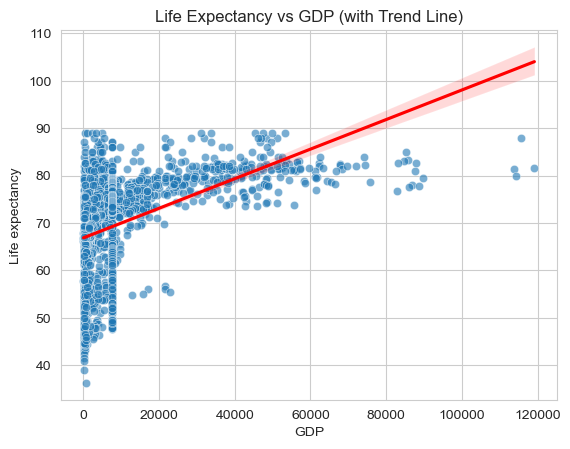

In [ ]:
# GDP vs LIFE EXPECTANCY

plt.figure()
sns.scatterplot(x=df["GDP"], y=df["Life expectancy"], alpha=0.6)
sns.regplot(x=df["GDP"], y=df["Life expectancy"], scatter=False, color="red")

plt.title("Life Expectancy vs GDP (with Trend Line)")
plt.show()

In [ ]:
df_numerical = df.select_dtypes(include=[np.number])
correlation_matrix = df_numerical.corr(method='pearson')

print("Pearson Correlation Matrix (first 5x5 rows/columns):")
print(correlation_matrix.head())

Pearson Correlation Matrix (first 5x5 rows/columns):
                     Year  Life expectancy  Adult Mortality  infant deaths  \
Year             1.000000         0.169623        -0.078861      -0.037415   
Life expectancy  0.169623         1.000000        -0.696359      -0.196535   
Adult Mortality -0.078861        -0.696359         1.000000       0.078747   
infant deaths   -0.037415        -0.196535         0.078747       1.000000   
Alcohol         -0.048168         0.391598        -0.190408      -0.113812   

                  Alcohol  percentage expenditure  Hepatitis B   Measles  \
Year            -0.048168                0.031400     0.089398 -0.082493   
Life expectancy  0.391598                0.381791     0.203771 -0.157574   
Adult Mortality -0.190408               -0.242814    -0.138591  0.031174   
infant deaths   -0.113812               -0.085612    -0.178783  0.501128   
Alcohol          1.000000                0.339634     0.075447 -0.051055   

                     

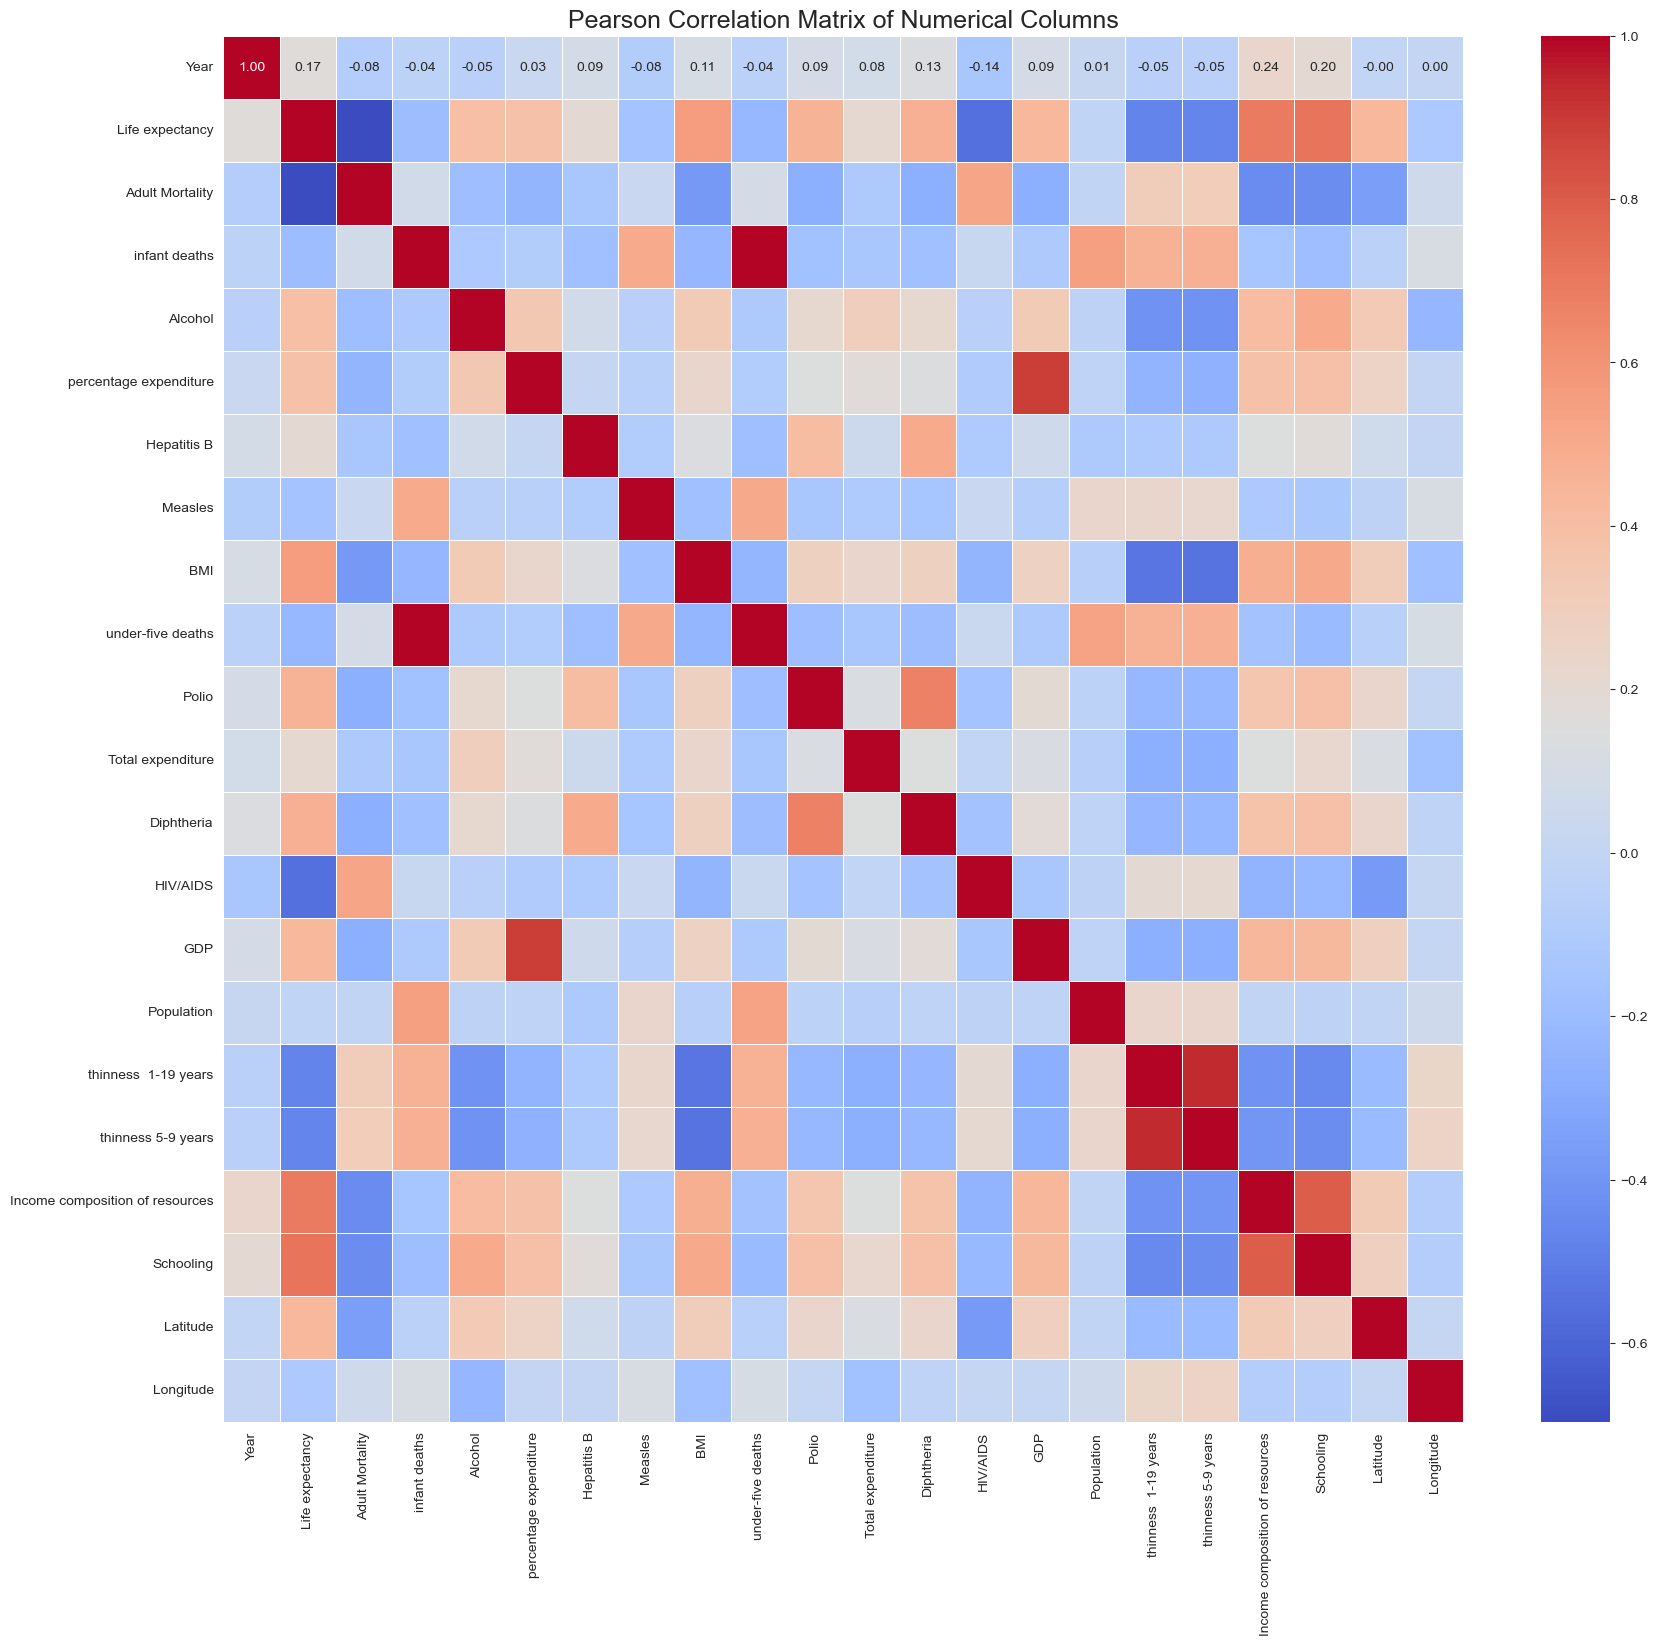

In [ ]:
plt.figure(figsize=(20, 18))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Pearson Correlation Matrix of Numerical Columns', fontsize=18)
plt.show()

### Overview of Pearson Correlation Matrix

The correlation heatmap provides valuable insights into the linear relationships between numerical variables in the dataset.

**Significant Positive Correlations:**
*   **Life expectancy** shows strong positive correlations with **Income composition of resources**, **Schooling**, and **BMI**. This suggests that countries with better income distribution, higher education levels, and higher average BMI tend to have higher life expectancy.
*   **infant deaths** and **under-five deaths** are highly positively correlated (almost 1.0), which is expected as infant deaths are a component of under-five deaths.
*   **GDP** and **percentage expenditure** exhibit a notable positive correlation, indicating that higher GDP often corresponds to a larger percentage of expenditure on health or other related sectors.

**Significant Negative Correlations:**
*   **Life expectancy** is strongly negatively correlated with **Adult Mortality** and **HIV/AIDS**. This is a logical finding: higher adult mortality and prevalence of HIV/AIDS are associated with lower life expectancy.
*   **thinness 1-19 years** and **thinness 5-9 years** are negatively correlated with **Life expectancy** and **BMI**, suggesting that lower life expectancy and BMI are associated with higher thinness rates among children and adolescents.
*   **Adult Mortality** shows a negative correlation with **Income composition of resources** and **Schooling**, implying that higher income equality and education levels are associated with lower adult mortality.

**Implications for Further Analysis:**
*   The strong correlations identified can be crucial for **feature selection** in predictive modeling. For instance, given the high correlation between 'infant deaths' and 'under-five deaths', one of them might be redundant in a model.
*   Variables highly correlated with 'Life expectancy' (e.g., 'Income composition of resources', 'Schooling', 'Adult Mortality', 'HIV/AIDS') are strong candidates for **primary predictors** in any model aiming to predict or understand life expectancy.
*   The presence of both positive and negative correlations highlights complex relationships within the data, which should be further investigated to understand causality and potential confounding factors.
*   Understanding these relationships can help in **identifying key drivers** of public health outcomes and informing policy decisions.

### **Life Expectancy by Country Status**

In [ ]:
fig = px.box(df, x="Status", y="Life expectancy", 
             color="Status",
             title="Life Expectancy by Country Status",
             points="all")
fig.show()



The boxplot compares life expectancy between developing and developed countries.

Developed countries have a higher median life expectancy, typically around 78–82 years, indicating better and more consistent health outcomes. In contrast, developing countries have a lower median life expectancy, around 65–70 years, with a much wider spread.

The larger variability in developing countries suggests significant inequality in health conditions, access to healthcare, and living standards. Additionally, several low-value outliers are observed in developing countries, indicating the presence of countries with extremely low life expectancy.

Overall, the visualization highlights a clear disparity between developed and developing countries, emphasizing the strong influence of socioeconomic development on life expectancy.

### **STEP 3: MULTIVARIATE ANALYSIS**

This step includes:

Correlation Analysis
Principal Component Analysis (PCA)
K-Means Clustering

### **1. CORRELATION ANALYSIS**

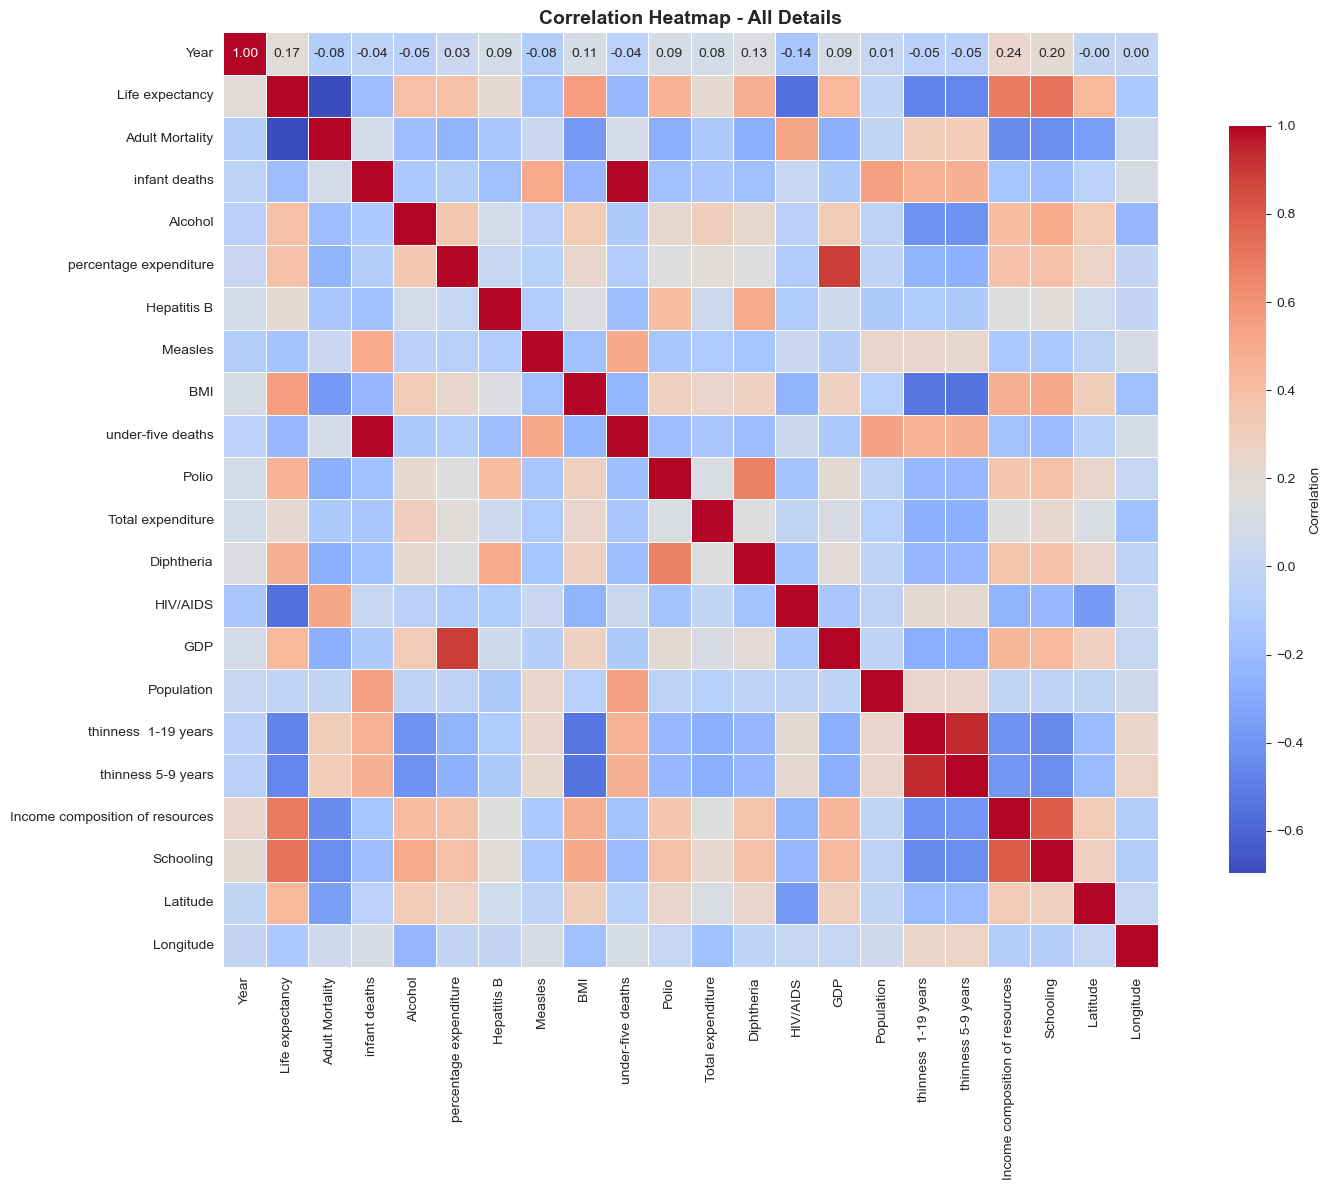

In [ ]:
# Compute correlation matrix
corr_matrix = df.corr(numeric_only=True)

# Plot heatmap with better formatting for all details
plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix, 
    cmap="coolwarm", 
    annot=True, 
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Correlation', 'shrink': 0.8},
    annot_kws={'size': 10}
)
plt.title("Correlation Heatmap - All Details", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Display correlation matrix as a formatted table
print("\n=== CORRELATION MATRIX (All Details) ===\n")
print(corr_matrix.round(3).to_string())

# Also save to CSV for reference
corr_matrix.to_csv("correlation_matrix.csv")
print("\nCorrelation matrix saved to 'correlation_matrix.csv'")


=== CORRELATION MATRIX (All Details) ===

                                  Year  Life expectancy  Adult Mortality  infant deaths  Alcohol  percentage expenditure  Hepatitis B  Measles    BMI  under-five deaths  Polio  Total expenditure  Diphtheria  HIV/AIDS    GDP  Population  thinness  1-19 years  thinness 5-9 years  Income composition of resources  Schooling  Latitude  Longitude
Year                             1.000            0.170           -0.079         -0.037   -0.048                   0.031        0.089   -0.082  0.108             -0.043  0.094              0.082       0.134    -0.140  0.093       0.015                -0.048              -0.051                            0.236      0.203    -0.002      0.000
Life expectancy                  0.170            1.000           -0.696         -0.197    0.392                   0.382        0.204   -0.158  0.559             -0.223  0.462              0.208       0.475    -0.556  0.430      -0.020                -0.472              

#### **Correlation Heatmap Shows**

- Shows relationships between variables  
- Red → positive correlation (increase together)  
- Blue → negative correlation (one increases, other decreases)  
- Near zero → weak or no relationship  


**Key Findings**

- Life expectancy is **positively related to**:
  - Income composition  
  - Schooling  
  - GDP  

- Life expectancy is **negatively related to**:
  - Adult mortality  
  - HIV/AIDS  
  - Infant deaths  
  - Under-five deaths  
  - Thinness  


**Strong Relationships**

- Infant deaths ↔ Under-five deaths  
- Thinness (1–19) ↔ Thinness (5–9)  


**Statistical Insight**

- Presence of **multicollinearity** (variables are highly correlated)


**Implication**

- Suggests need for **dimensionality reduction (PCA)**

### **2. PRINCIPAL COMPONENT ANALYSIS (PCA)**

**Standardize data**

In [ ]:
df.columns

Index(['Country_x', 'Year', 'Status', 'Life expectancy', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure',
       'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years',
       'thinness 5-9 years', 'Income composition of resources', 'Schooling',
       'Country_matched', 'Country_y', 'Latitude', 'Longitude'],
      dtype='object')

In [ ]:
feature_data = df.select_dtypes(include=[np.number]).drop(columns=["Life expectancy"])
# Remove rows with missing values before standardization
feature_data = feature_data.dropna()
# Standardize the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(feature_data)

**Apply PCA**

In [31]:

pca = PCA()
pca_data = pca.fit_transform(scaled_data)
pca_df = pd.DataFrame(data=pca_data, columns=[f"PC{i+1}" for i in range(pca_data.shape[1])])
pca_df

NameError: name 'scaled_data' is not defined

**Explained Variance ratio**

In [ ]:
explained_variance = pca.explained_variance_ratio_
print("Explained Variance Ratio by Each Principal Component:")
for i, var in enumerate(explained_variance):
    print(f"PC{i+1}: {var:.4f}")
    

Explained Variance Ratio by Each Principal Component:
PC1: 0.2918
PC2: 0.1361
PC3: 0.0929
PC4: 0.0717
PC5: 0.0645
PC6: 0.0546
PC7: 0.0447
PC8: 0.0410
PC9: 0.0382
PC10: 0.0307
PC11: 0.0296
PC12: 0.0260
PC13: 0.0221
PC14: 0.0208
PC15: 0.0165
PC16: 0.0102
PC17: 0.0055
PC18: 0.0032
PC19: 0.0001


**VISUALIZE CLUSTERS (PCA)**

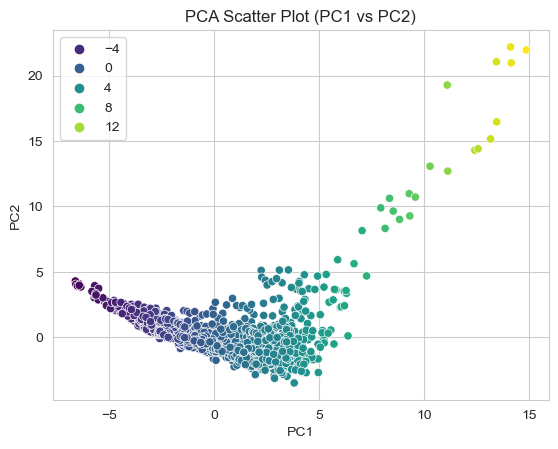

In [ ]:
plt.figure()
sns.scatterplot(
    x=pca_data[:, 0], 
    y=pca_data[:, 1], 
    hue=pca_data[:, 0],  # Color by the first principal component
    palette="viridis"
)

plt.title("PCA Scatter Plot (PC1 vs PC2)")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.show()

**No Relationship which is good**

#### **Number of PC to go with**

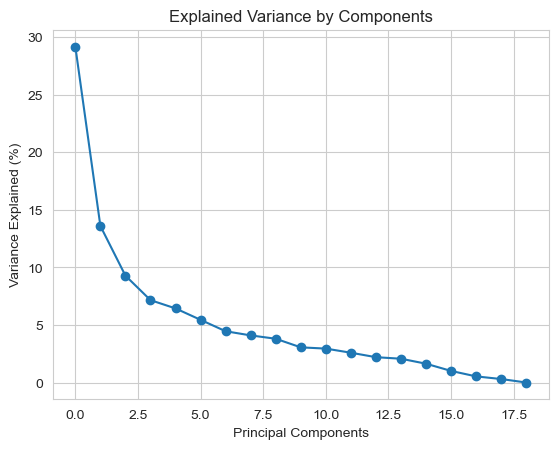

In [ ]:
# Explained variance in percentage
explained_variance = pca.explained_variance_ratio_ * 100

plt.figure()
plt.plot(explained_variance, marker='o')

plt.title("Explained Variance by Components")
plt.xlabel("Principal Components")
plt.ylabel("Variance Explained (%)")

plt.show()

**CUMULATIVE VARIANCE**

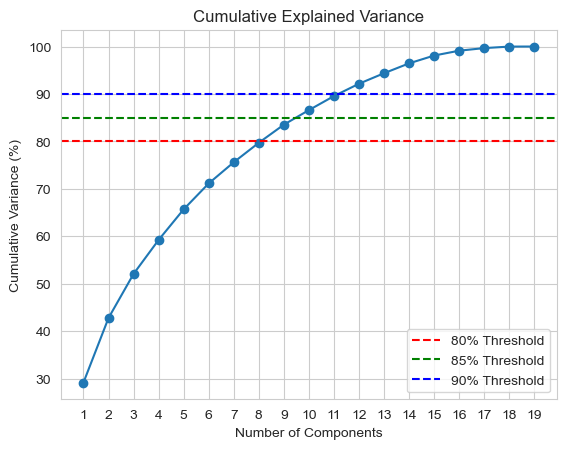

In [ ]:
# Cumulative variance (percentage)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_) * 100
components = range(1, len(cumulative_variance) + 1)

plt.figure()
plt.plot(components, cumulative_variance, marker='o')

# Horizontal threshold lines
plt.axhline(y=80, color='red', linestyle='--', label='80% Threshold')
plt.axhline(y=85, color='green', linestyle='--', label='85% Threshold')
plt.axhline(y=90, color='blue', linestyle='--', label='90% Threshold')

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance (%)")

plt.xticks(components)
plt.legend()

plt.show()

**Selection of Principal Components**

The cumulative explained variance plot was used to determine the optimal number of principal components. Horizontal threshold lines at 80%, 85%, and 90% were added to guide selection.

The number of components was chosen based on the point where the cumulative variance exceeds the desired threshold, ensuring that most of the information in the dataset is retained while reducing dimensionality.

**KAISER CRITERION**

In [ ]:
eigenvalues = pca.explained_variance_.round(2)
print("Eigenvalues of Each Principal Component:")   
for i, eigenvalue in enumerate(eigenvalues):
    print(f"PC{i+1}: {eigenvalue:.2f}")

Eigenvalues of Each Principal Component:
PC1: 5.55
PC2: 2.59
PC3: 1.77
PC4: 1.36
PC5: 1.23
PC6: 1.04
PC7: 0.85
PC8: 0.78
PC9: 0.73
PC10: 0.58
PC11: 0.56
PC12: 0.49
PC13: 0.42
PC14: 0.40
PC15: 0.31
PC16: 0.19
PC17: 0.10
PC18: 0.06
PC19: 0.00


**we Keep the first 6 components with eigenvalue > 1**

**Scree plot**

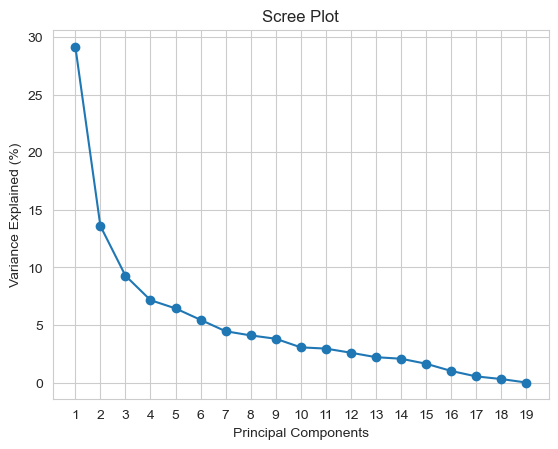

In [ ]:
# Scree Plot

explained_variance = pca.explained_variance_ratio_ * 100
components = range(1, len(explained_variance) + 1)

plt.figure()
plt.plot(components, explained_variance, marker='o')

plt.title("Scree Plot")
plt.xlabel("Principal Components")
plt.ylabel("Variance Explained (%)")

plt.xticks(components)

plt.show()

**The elbow is at 3 so we can keep the first 3 principal components for further analysis.**

### **Unsupervisded learning**

#### **3. K-MEANS Clustering**

**FIND OPTIMAL K (ELBOW METHOD)**

In [ ]:
pca_df.columns

Index(['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10',
       'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'PC16', 'PC17', 'PC18', 'PC19'],
      dtype='object')

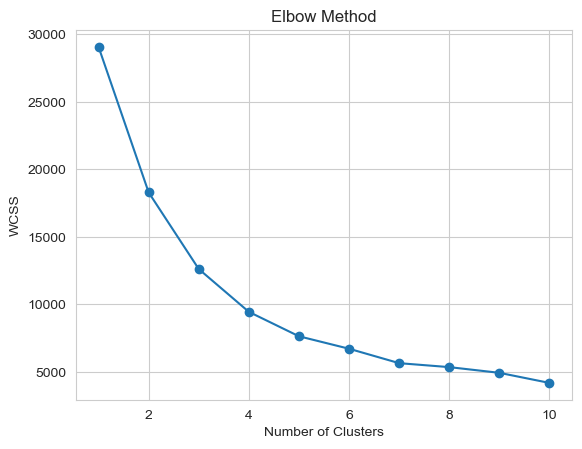

In [ ]:

# Elbow method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(pca_df[["PC1", "PC2", "PC3"]])
    wcss.append(kmeans.inertia_)

# Plot elbow graph
plt.figure()
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

 
**Optimal Number of Clusters**

- The “elbow point” appears around **K = 3**.   

**APPLY K-MEANS**

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
df["Cluster"] = kmeans.fit_predict(pca_df[["PC1", "PC2", "PC3"]])

**VISUALIZE CLUSTERS (PCA)**

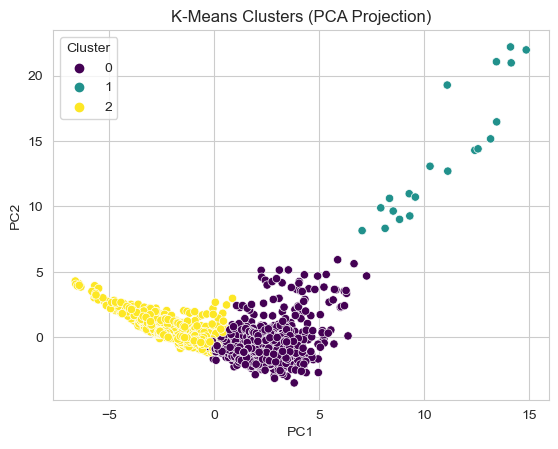

In [ ]:
plt.figure()
sns.scatterplot(
    x=pca_data[:, 0], 
    y=pca_data[:, 1], 
    hue=df["Cluster"], 
    palette="viridis"
)

plt.title("K-Means Clusters (PCA Projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.show()

### K-Means Clustering Analysis

K-Means clustering was applied to group countries based on their characteristics. The optimal number of clusters was determined using the elbow method, which suggested three clusters.

The results show that countries can be divided into distinct groups with similar patterns in terms of health, economic development, and demographic indicators.

Cluster analysis reveals meaningful differences between groups, likely representing varying levels of development and healthcare access. This highlights global disparities and provides insights into how countries compare across multiple dimensions.

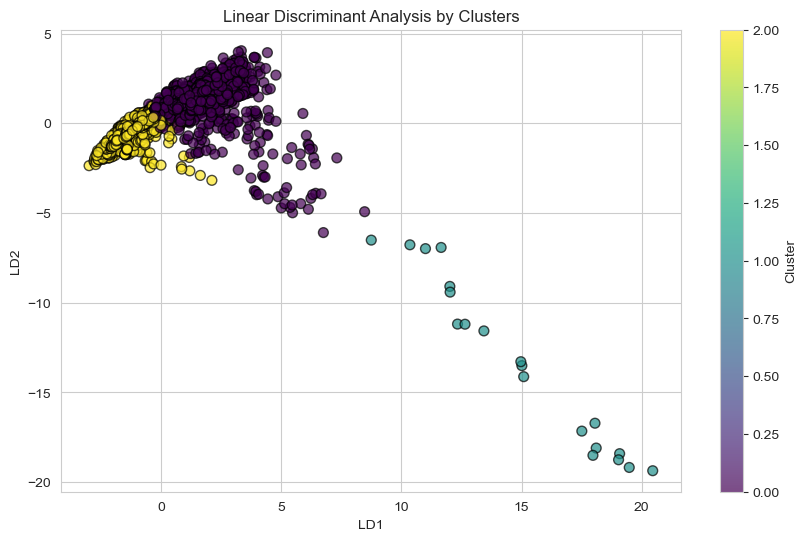

LDA Explained Variance Ratio: [0.64541978 0.35458022]
Cumulative Explained Variance: [0.64541978 1.        ]


In [ ]:
# INSERT AFTER K-Means visualization

### **3. LINEAR DISCRIMINANT ANALYSIS (LDA)**

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Prepare data for LDA (using clusters as target)
lda = LinearDiscriminantAnalysis(n_components=2)
lda_data = lda.fit_transform(scaled_data, df["Cluster"])

# Visualization
plt.figure(figsize=(10, 6))
scatter = plt.scatter(lda_data[:, 0], lda_data[:, 1], c=df["Cluster"], 
                     cmap="viridis", s=50, alpha=0.7, edgecolors='k')
plt.title("Linear Discriminant Analysis by Clusters")
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.colorbar(scatter, label="Cluster")
plt.show()

# Print LDA explained variance
print("LDA Explained Variance Ratio:", lda.explained_variance_ratio_)
print("Cumulative Explained Variance:", np.cumsum(lda.explained_variance_ratio_))

### **STEP 4: Supervised Learning**

**Multilinear Regression**

###### **STEP 4.1: Define Target and Features**

In [ ]:
# Feature matrix
X = pca_df.select_dtypes(include=[np.number])
print(X.columns)
#Target variable
y = df["Life expectancy"]

Index(['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10',
       'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'PC16', 'PC17', 'PC18', 'PC19'],
      dtype='object')


##### **STEP 4.3: Split Data (Train/Test)**
The dataset was divided into training and testing sets.  
- 80% of the data was used for training the model  
- 20% of the data was used for testing the model 

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (2350, 19)
X_test shape: (588, 19)
y_train shape: (2350,)
y_test shape: (588,)


#### **Step 4.4: Train the Linear Regression Model**


In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


##### **STEP 4.5: MAKE PREDICTIONS**

In [ ]:
y_pred = model.predict(X_test)
print("First 5 Predictions:")
print(y_pred[:5])

First 5 Predictions:
[67.16686177 76.70596641 75.87756282 78.21436998 46.81186794]


##### **STEP 4.6: Evaluation**

In [ ]:
# Compare actual vs predicted
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head()

,Actual,Predicted
0,73.7,67.166862
1,75.9,76.705966
2,74.2,75.877563
3,76.8,78.214370
4,51.9,46.811868


**MSE, R2**

In [ ]:
# Step 4.6: Evaluate Model

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("R-squared (R²):", r2)

Mean Squared Error (MSE): 15.360886871284759
R-squared (R²): 0.8226947795445848


The model explains 82% of the data with moderate error, indicating good and reliable performance.


=== RANDOM FOREST REGRESSOR ===
Mean Squared Error (MSE): 8.348906379197436
R-squared (R²): 0.9036315612158783


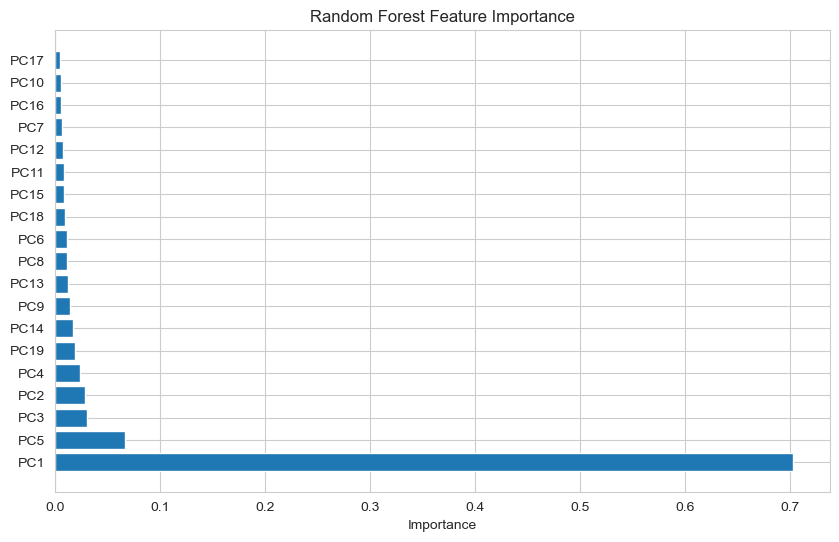

In [ ]:
# INSERT AFTER Linear Regression evaluation

### **4.7: Additional ML Algorithms**

#### **A. Random Forest Regressor**

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_r2 = r2_score(y_test, y_pred_rf)

print("\n=== RANDOM FOREST REGRESSOR ===")
print("Mean Squared Error (MSE):", rf_mse)
print("R-squared (R²):", rf_r2)

# Feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

In [ ]:
#### **C. Support Vector Machine (SVM)**

from sklearn.svm import SVR

svm_model = SVR(kernel='rbf', C=100, gamma=0.1)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

svm_mse = mean_squared_error(y_test, y_pred_svm)
svm_r2 = r2_score(y_test, y_pred_svm)

print("\n=== SUPPORT VECTOR MACHINE (SVM) ===")
print("Mean Squared Error (MSE):", svm_mse)
print("R-squared (R²):", svm_r2)


=== SUPPORT VECTOR MACHINE (SVM) ===
Mean Squared Error (MSE): 5.65087654937531
R-squared (R²): 0.9347739540855348


In [ ]:
# INSERT BEFORE Model Comparison section

#### **B. Decision Tree Regressor**

from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42, max_depth=10)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

dt_mse = mean_squared_error(y_test, y_pred_dt)
dt_r2 = r2_score(y_test, y_pred_dt)

print("\n=== DECISION TREE REGRESSOR ===")
print("Mean Squared Error (MSE):", dt_mse)
print("R-squared (R²):", dt_r2)


=== DECISION TREE REGRESSOR ===
Mean Squared Error (MSE): 19.577498206010826
R-squared (R²): 0.77402394376908



=== MODEL COMPARISON ===
               Model        MSE        R²
0  Linear Regression  15.360887  0.822695
1      Random Forest   8.348906  0.903632
2      Decision Tree  19.577498  0.774024
3                SVM   5.650877  0.934774


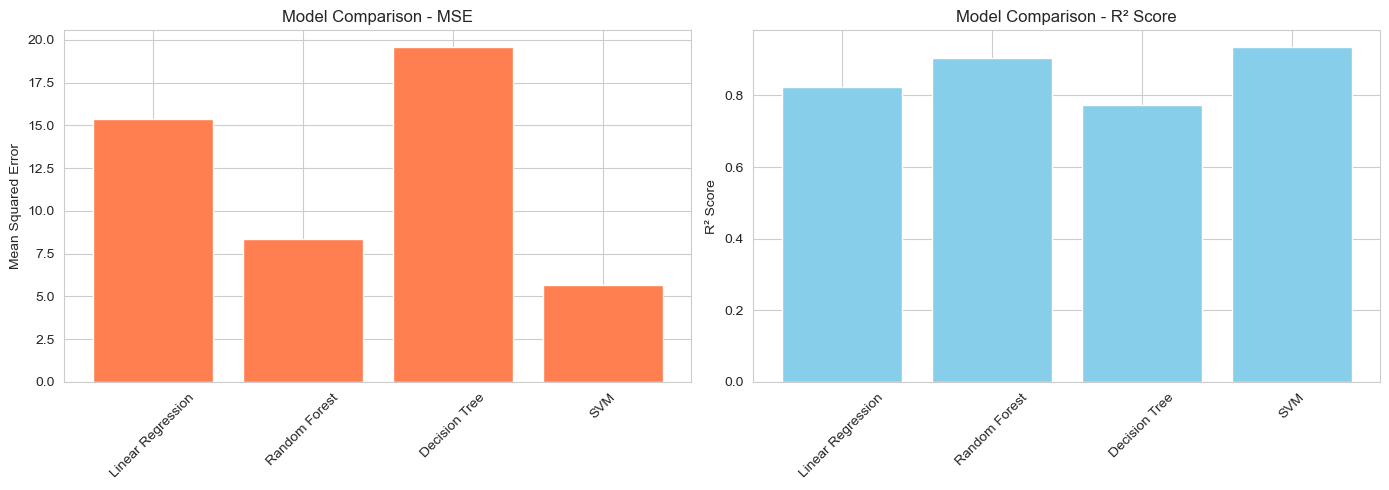

In [ ]:
#### **D. Model Comparison**

# Create comparison dataframe
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Decision Tree", "SVM"],
    "MSE": [mse, rf_mse, dt_mse, svm_mse],
    "R²": [r2, rf_r2, dt_r2, svm_r2]
})

print("\n=== MODEL COMPARISON ===")
print(model_comparison)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(model_comparison["Model"], model_comparison["MSE"], color="coral")
axes[0].set_title("Model Comparison - MSE")
axes[0].set_ylabel("Mean Squared Error")
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(model_comparison["Model"], model_comparison["R²"], color="skyblue")
axes[1].set_title("Model Comparison - R² Score")
axes[1].set_ylabel("R² Score")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# REPLACE the dashboard section with this:

### **STEP 5: INTERACTIVE DASHBOARD**

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

#### **Dashboard 1: Life Expectancy Overview**



In [ ]:
fig1 = px.scatter(df, x="GDP", y="Life expectancy", 
                  size="Population", color="Status",
                  hover_data=["Country", "Year"],
                  title="Interactive: Life Expectancy vs GDP",
                  labels={"GDP": "GDP (USD)", "Life expectancy": "Life Expectancy (years)"})
fig1.show()



In [ ]:
#### **Dashboard 2: Cluster Analysis**

fig2 = px.scatter(df, x=pca_data[:, 0], y=pca_data[:, 1],
                  color=df["Cluster"].astype(str),
                  title="PCA Clusters - Interactive View")


In [ ]:
### **Dashboard 3: Status Comparison**

fig3 = px.box(df, x="Status", y="Life expectancy", 
              color="Status",
              title="Life Expectancy by Country Status",
              points="all")
fig3.show()


In [ ]:


#### **Dashboard 4: Predictions vs Actual**

prediction_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Model": "Linear Regression"
})

fig4 = px.scatter(prediction_df, x="Actual", y="Predicted",
                  title="Actual vs Predicted Life Expectancy",
                  trendline="ols")
fig4.add_trace(go.Scatter(
    x=[prediction_df["Actual"].min(), prediction_df["Actual"].max()],
    y=[prediction_df["Actual"].min(), prediction_df["Actual"].max()],
    mode='lines',
    name='Perfect Prediction',
    line=dict(dash='dash', color='red')
))
fig4.show()